# 01 · Market sizing

The textbook top-down size of US upstream is *US crude output x WTI*. That needs a production volume series. EIA is unavailable here (no `EIA_API_KEY`) and the FRED snapshot contains prices, rates and indices but no volumes, so we **do not** invent one. Instead we build a bottom-up proxy from what companies actually reported in their 10-Ks, read point-in-time by filing date.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.analysis import sizing
res = sizing.compute()
res['topdown_status']

{'available': False,
 'requires': 'US crude oil field production volume (EIA PET MCRFPUS2), not in snapshot',
 'reason': 'EIA_API_KEY not set; FRED snapshot has no production volume series'}

## Reported revenue by segment ($bn, fiscal year)

In [3]:
pd.DataFrame(res['segment_revenue_usd']).sort_index() / 1e9

,majors,upstream,midstream,refiners,services
2016,339.460,30.375,61.270,223.215,56.779
2017,418.669,37.845,74.433,271.067,68.239
2018,495.278,53.935,89.510,314.580,79.687
2019,448.124,55.028,85.787,326.765,79.163
2020,294.978,40.790,66.915,198.820,58.751
2021,493.933,63.601,111.194,345.436,58.726
2022,738.426,91.148,142.428,523.826,69.544
2023,601.672,71.012,122.504,440.544,81.659
2024,607.122,72.723,129.972,411.898,87.062
2025,580.213,76.439,148.052,387.762,85.625


In [4]:
display(Markdown(f"FY{res['latest_fiscal_year']} total: **${res['total_revenue_latest_usd']/1e9:,.0f}bn**; missing: {', '.join(res['missing_revenue_latest_year']) or 'none'}"))
pd.Series(res['segment_share_latest'], name='share').map('{:.1%}'.format)

FY2025 total: **$1,278bn**; missing: APA

majors       45.4%
upstream      6.0%
midstream    11.6%
refiners     30.3%
services      6.7%
Name: share, dtype: object

## Why this is a proxy, not a market size

In [5]:
for c in res['caveats']:
    print('-', c)

- Revenue is global and consolidated, not US-only.
- Segments double count: refiners' revenue includes crude bought from producers.
- Majors' and refiners' revenue include pass-through product sales, so revenue overstates value added; it measures scale of flows, not market value.
- Survivor universe of 18 names: excludes private producers and acquired/bankrupt names.
- Companies without a standard us-gaap revenue tag are left out, not estimated.


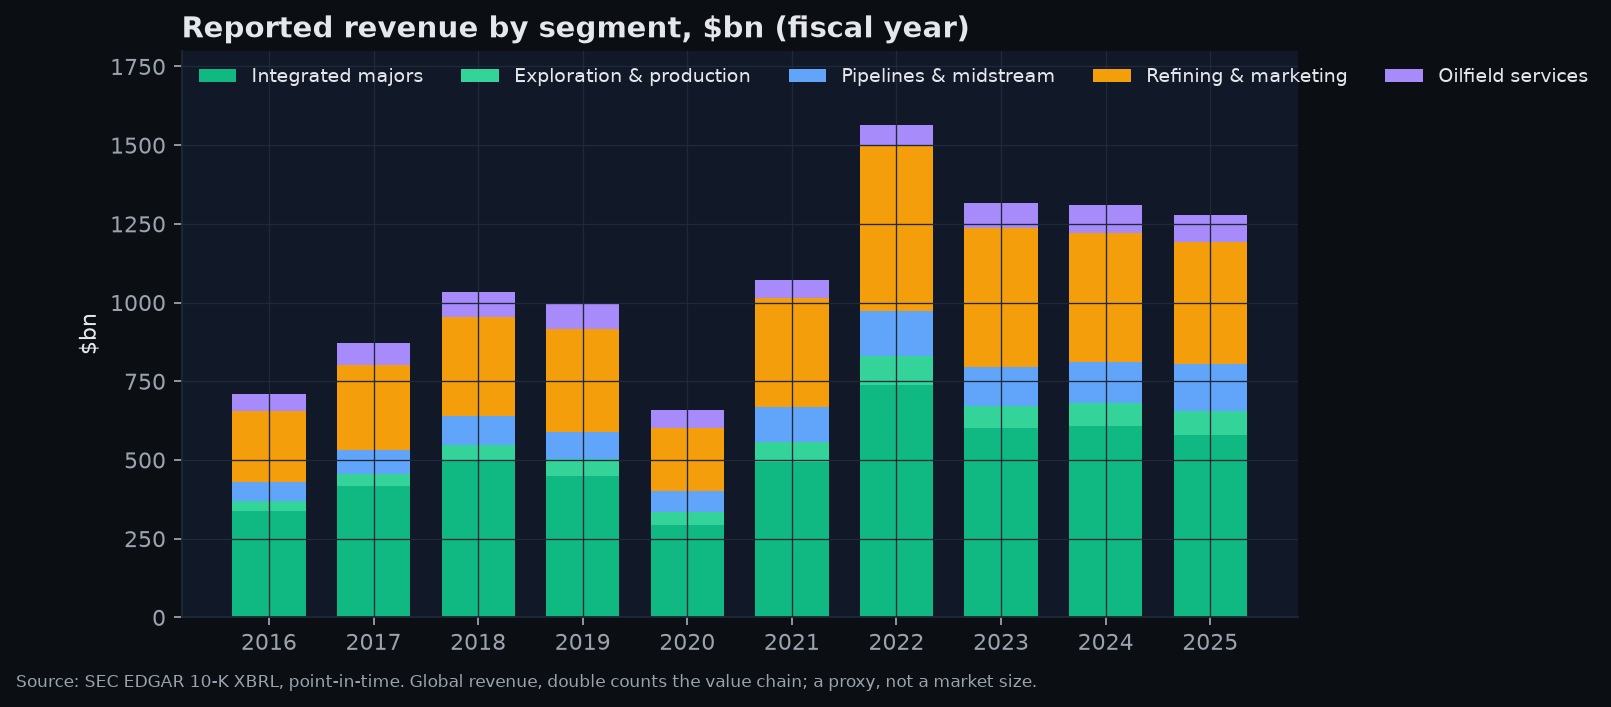

In [6]:
Image('../docs/img/segment_revenue.png')

**Takeaway.** Revenue is dominated by majors and refiners because their sales pass crude and products through at market prices; upstream and services are small by revenue but, as notebook 02 shows, carry most of the oil risk. A true top-down size waits on an EIA key.